# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.1 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 6.0 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [11]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [12]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [13]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [14]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [15]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [16]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,16.77,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.59,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.75,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.83,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

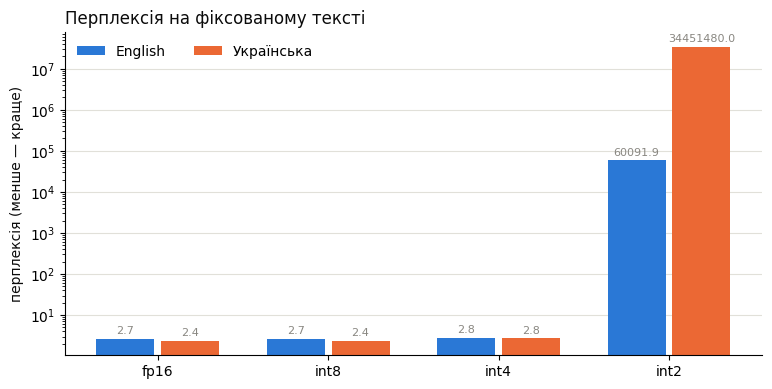

In [17]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [18]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [19]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [20]:
VOTES = {1: "", 2: "", 3: "", 4: "", 5: ""}

In [21]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [22]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---
# Лабораторна робота №4. Мої спостереження та практична частина

**Тема застосунку:** локальний помічник для визначення порядку дій працівника поштового відділення у нестандартних ситуаціях.

Нижче подано теоретичні пояснення та код для фіксації власних результатів. Результати GPU, голоси у сліпому порівнянні, швидкість локальної моделі та персональні характеристики комп'ютера потрібно отримати під час виконання лабораторної, а не переносити з іншого обладнання. Приклади процедур у застосунку навчальні, не є внутрішнім регламентом компанії.


### 0.1.1. Помилка підрахунку літер

Модель може впевнено помилятися навіть у підрахунку символів. Вона оперує токенами, які не обов'язково збігаються з літерами, і не гарантує посимвольного аналізу. Додаткові міркування також не означають запуск точного алгоритму. Програмний підрахунок дає контрольну відповідь: у слові «трансформер» літера «р» зустрічається тричі. Після запуску секції 1.5 треба вписати, що відповіла модель у кожному режимі.

In [23]:
word = 'трансформер'
print('Символи:', list(word))
print('Точний підрахунок:', word.count('р'))

Символи: ['т', 'р', 'а', 'н', 'с', 'ф', 'о', 'р', 'м', 'е', 'р']
Точний підрахунок: 3


### 0.1.2. Зміна метрик за різних точностей

Зменшення кількості біт знижує пам'ять для ваг, але може погіршити якість. Для int8 та int4 зміни часто помірні, а int2 може руйнувати генерацію. Найбільший стрибок слід визначити за фактичною таблицею: показники для переходів fp16→int8, int8→int4 та int4→int2 порівнюються окремо. BLEU і chrF залежать від еталонних формулювань і можуть трохи коливатися навіть без очевидної зміни якості.

In [25]:
print(summary.to_string())

      памʼять моделі, GB  пік VRAM, GB  tokens/s  перплексія, English  перплексія, Українська  chrF перекладу  BLEU перекладу
fp16                8.04          8.64     16.77                 2.67                    2.40           55.22           23.71
int8                4.42          5.01      5.59                 2.67                    2.40           58.25           26.17
int4                2.73          3.32      2.75                 2.81                    2.76           55.34           29.79
int2                1.81          2.39      2.83             60091.86             34451480.00            0.19            0.12


### 0.1.3. Англійська й українська при квантизації

Порівнюю не самі значення перплексії різних мов, а збільшення відносно fp16 **в межах кожної мови**. Це потрібно, тому що токенізатор може створювати різну кількість токенів для українського та англійського тексту. Якщо коефіцієнт зростання для української більший, це узгоджується з ризиком погіршення якості для менш представлених мов; один тест не доводить універсального правила.

In [26]:
for lang in PPL_TEXT:
    base = records['fp16'][f'перплексія, {lang}']
    print(lang, {k: round(v[f'перплексія, {lang}'] / base, 2) for k,v in records.items()})

English {'fp16': 1.0, 'int8': 1.0, 'int4': 1.05, 'int2': 22475.9}
Українська {'fp16': 1.0, 'int8': 1.0, 'int4': 1.15, 'int2': 14353761.81}


### 0.1.4. Сліпе оцінювання проти автоматичних метрик

Після секції 2.5 заповнюю голоси без знання назви моделі. Якщо ручні рішення не збігаються з перевагою в BLEU/chrF, це очікувано: метрики перекладу та оцінювання вільних текстів мають різні критерії. Після виконання потрібно вказати власні числа голосів і один приклад, де відповідь зручніша, але метрика цього не відображає.

In [27]:
if all(v in ('A','B','=') for v in VOTES.values()):
    print('Голоси внесено у секції 2.5:', VOTES)
else:
    print('Спочатку заповніть VOTES у секції 2.5.')

Спочатку заповніть VOTES у секції 2.5.


### 0.1.5. Семантично правильний переклад і метрики

BLEU сильніше прив'язаний до збігу послідовностей слів, тоді як chrF аналізує символьні n-грами. Через синоніми й перефразування обидва показники можуть зменшуватися, хоча зміст переданий правильно. Для відповіді необхідно вибрати **один реальний рядок** із таблиці 2.4, навести еталон і переклад та зафіксувати отримані BLEU і chrF. Без результатів цього запуску конкретні числа не зазначаю.

In [28]:
for i,(src,ref) in enumerate(TRANSLATION):
    print('Джерело:',src,'| Еталон:',ref)
    print('fp16:',records['fp16']['переклади'][i])
    print('int4:',records['int4']['переклади'][i]); print('-'*40)

Джерело: The meeting has been moved to Thursday at three o'clock. | Еталон: Зустріч перенесли на четвер на третю годину.
fp16: Зустріч була перенесена на четвер, о 15 годин.
int4: Зустріч була перенесена на четвер, о 15 годин.
----------------------------------------
Джерело: Please send me the report by the end of the day. | Еталон: Будь ласка, надішліть мені звіт до кінця дня.
fp16: Надішліть мені звіт до кінця дня.
int4: Надішліть мені звіт до кінця дня.
----------------------------------------
Джерело: The library is closed on Sundays and public holidays. | Еталон: Бібліотека не працює в неділю та у святкові дні.
fp16: Бібліотека закривається у неділі та дні відпочинку.
int4: Бібліотека відкрита тільки з 1 по 7.
----------------------------------------
Джерело: Our team fixed the bug, but the tests are still failing. | Еталон: Наша команда виправила помилку, але тести все ще не проходять.
fp16: Наша команда виправила баг, але тестування все ще не працюють.
int4: Наша команда виправ

### 0.1.6. Пам’ять та швидкість

Формула `N × бітність / 8` оцінює тільки ваги. Реальна модель містить масштаби квантизації, метадані, деякі шари підвищеної точності та допоміжні буфери, тому пам'ять не ділиться рівно на 2, 4 і 8. Швидкість теж не зобов'язана зростати: деквантизація та неефективні GPU-ядра можуть зробити int4 повільнішою за fp16.

In [29]:
base=records['fp16']['памʼять моделі, GB']
for name,r in records.items():
    print(name, 'економія', round(base / r['памʼять моделі, GB'],2),'x',
          '| швидкість', round(r['tokens/s'],2),'tok/s')

fp16 економія 1.0 x | швидкість 16.77 tok/s
int8 економія 1.82 x | швидкість 5.59 tok/s
int4 економія 2.94 x | швидкість 2.75 tok/s
int2 економія 4.44 x | швидкість 2.83 tok/s


### 0.1.7. Чому Base-модель задає нові питання

Base-модель продовжує текст за статистичними закономірностями й не навчена обов'язково реагувати на інструкції. Щоб наблизити її до потрібного формату, використовую few-shot: пара «Запитання — відповідь» дає приклад, який модель може продовжити. Потрібно показати фактичну генерацію після запуску клітинки.

In [30]:
prompt = 'Запитання: Столиця Італії?\nВідповідь: Рим\n\nЗапитання: Столиця Німеччини?\nВідповідь:'
print(generate_raw(BASE_MODEL, prompt, max_tokens=60))

 Берлін

Запитання: Столиця Франції?
Відповідь: Паризький

Запитання: Столиця Польщі?
Відповідь:


### 0.1.8. Токени та час міркування

Для порівняння слід використовувати однаковий промпт і налаштування генерації. `eval_count` у Ollama містить згенеровані токени, а `eval_duration` показує час генерації. Режим thinking може мати значно більший вивід через приховану чи видиму послідовність міркувань. Англійська мова міркувань можлива через дані й формат навчання, хоча кінцева відповідь українською.

In [31]:
question = 'У коробці було 12 маркерів. Додали 3 набори по 4, а 5 забрали. Скільки залишилося?'
for thinking in (False,True):
    r=chat(INSTRUCT_MODEL,question,think=thinking)
    print(thinking,'токени:',r.get('eval_count'),'секунди:',round(r.get('eval_duration',0)/1e9,2),
          'відповідь:',r['message']['content'])

False токени: 141 секунди: 1.42 відповідь: У коробці було **12 маркерів**.

Додали **3 набори по 4 маркера**:
$$
3 \times 4 = 12 \text{ маркерів}
$$
Таким чином, стало:
$$
12 + 12 = 24 \text{ маркерів}
$$

Потім **5 маркерів забрали**:
$$
24 - 5 = 19 \text{ маркерів}
$$

**Відповідь:**  
$$
\boxed{19}
$$
True токени: 418 секунди: 4.21 відповідь: Після додавання 3 наборів по 4 маркери (3 × 4 = 12) у коробці стало 12 + 12 = 24 маркери. Потім відняли 5 маркерів: 24 − 5 = 19. 

**Відповідь: 19**


### 0.1.9. Приклад, де режим thinking допомагає

Не кожна задача показує перевагу reasoning. Для виконання вимоги підбираю кілька незалежних арифметичних або логічних задач та перевіряю обидва режими. Зараховується лише той приклад, де звичайний режим дав неправильний результат, а thinking — правильний. Після виконання треба навести сам промпт і фактичні відповіді.

In [32]:
cases = [
  ('Є 5 коробок по 7 ручок. 8 ручок віддали, а 2 коробки по 3 ручки додали. Скільки ручок?',33),
  ('Число збільшили на 25%, а потім зменшили на 20%. Було 80. Скільки стало?',80),
  ('Чотири працівники пакують по 6 коробок за годину. За 2 години один працював лише годину. Скільки коробок?',42),
]
for question,expected in cases:
    answers={}
    for mode in (False,True):
        r=chat(INSTRUCT_MODEL,question,think=mode,max_tokens=3500)
        answers[mode]=r['message']['content'].strip()
    print('Питання:',question,'| правильна відповідь:',expected,'| без:',answers[False],'| thinking:',answers[True])

Питання: Є 5 коробок по 7 ручок. 8 ручок віддали, а 2 коробки по 3 ручки додали. Скільки ручок? | правильна відповідь: 33 | без: Розглянемо задачу крок за кроком:

1. **Підсумок початкової ситуації:**
   - Є **5 коробок**, по **7 ручок**.
   - Загальна кількість ручок:
     $$
     5 \times 7 = 35 \text{ ручок}
     $$

2. **Віддача ручок:**
   - **8 ручок віддали**.
   - Загальна кількість ручок пі向:
     $$
     35 - 8 = 27 \text{ ручок}
     $$

3. **Доданок ручок:**
   - **2 коробки**, по **3 ручки**.
   - Загальна кількість ручок пі向:
     $$
     27 + (2 \times 3) = 27 + 6 = 33 \text{ ручок}
     $$

**Відповідь:**
$$
\boxed{33} \text{ ручок}
$$ | thinking: Щоб визначити загальне число ручок, виконуємо наступні кроки:

1. **Підрахунок початкового числа ручок:**
   - У нас є 5 коробок, кожна з яких містить 7 ручок.
   - Підрахунок: $5 \times 7 = 35$ ручок.

2. **Віддача ручок:**
   - Віддали 8 ручок.
   - Після віддалення: $35 - 8 = 27$ ручок.

3. **Додавання нових ручок:**
   - Д

### 0.1.10. Навіщо фіксувати temperature і seed

Нульова температура зменшує випадковість під час вибору наступного токена, а seed фіксує початковий стан генератора випадкових чисел, якщо конкретний рантайм його застосовує. Це допомагає порівнювати моделі в більш однакових умовах. Повної побітової відтворюваності на різному GPU чи різних версіях бібліотек seed не гарантує.

### 0.1.11. FP16 і BF16 на GPU T4

Tesla T4 має compute capability 7.5 та прискорює FP16, але не забезпечує нативної підтримки BF16 так, як новіші архітектури NVIDIA. BF16 може працювати через програмний шлях, що не рівнозначно апаратному прискоренню. У демонстрації обрано FP16, оскільки цей формат краще відповідає T4.

In [33]:
print('GPU:',torch.cuda.get_device_name(0))
print('Compute capability:',torch.cuda.get_device_capability(0))
print('BF16 доступний або емуляція:',torch.cuda.is_bf16_supported())
try:
    print('Нативний BF16:',torch.cuda.is_bf16_supported(including_emulation=False))
except TypeError:
    print('Поточна версія torch не підтримує параметр including_emulation')

GPU: Tesla T4
Compute capability: (7, 5)
BF16 доступний або емуляція: True
Нативний BF16: False


### 0.1.12. Оцінка розміру FP16

Модель із приблизно 4 млрд параметрів у FP16 потребує орієнтовно `4 × 10⁹ × 2 = 8 × 10⁹ байт`, тобто приблизно 8 GB десяткових одиниць для ваг. Відмінність від `memory_allocated()` пояснюється реальною кількістю параметрів, додатковими тензорами та алокаціями.

In [34]:
estimated = 4_000_000_000 * 2 / 1e9
print('Оцінка GB:',estimated,'| Виміряно fp16 GB:',records['fp16']['памʼять моделі, GB'])

Оцінка GB: 8.0 | Виміряно fp16 GB: 8.044955648


### 0.1.13. Перплексія для випадкового тексту

Перплексія — експонента середньої крос-ентропійної втрати при передбаченні наступного токена. Вона показує, наскільки несподіваним є текст для моделі. Випадкове перемішування слів зменшує передбачуваність і зазвичай збільшує PPL. Абсолютні значення для різних мов порівнювати некоректно через токенізацію і відмінність корпусів.

In [35]:
import random
random.seed(41)
words=PPL_TEXT['English'].split()
random.shuffle(words)
shuffled=' '.join(words)
print('Потрібно обчислити perplexity(fp16_model, shuffled) після завантаження FP16-моделі.')
fp16_again=AutoModelForCausalLM.from_pretrained(MODEL_ID,dtype=DTYPE,device_map=DEVICE)
print('Осмислений текст:',round(perplexity(fp16_again,PPL_TEXT['English']),2))
print('Перемішаний текст:',round(perplexity(fp16_again,shuffled),2))
del fp16_again
gc.collect(); torch.cuda.empty_cache()

Потрібно обчислити perplexity(fp16_model, shuffled) після завантаження FP16-моделі.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Осмислений текст: 2.67
Перемішаний текст: 289.12


### 0.1.14. Чому VRAM-пік більший за ваги

Вага моделі — лише одна складова використання GPU. При генерації додаються KV-cache, активації, вхідні токени, проміжні буфери, CUDA-контекст і тимчасові тензори. Пік показує найвище значення, а не постійне зайняття пам'яті.

In [36]:
for name,r in records.items():
  print(name,'ваги',round(r['памʼять моделі, GB'],2),'GB','пікова VRAM',round(r['пік VRAM, GB'],2),'GB')

fp16 ваги 8.04 GB пікова VRAM 8.64 GB
int8 ваги 4.42 GB пікова VRAM 5.01 GB
int4 ваги 2.73 GB пікова VRAM 3.32 GB
int2 ваги 1.81 GB пікова VRAM 2.39 GB


### 0.1.15. Значущість п’яти голосів

П'ять суб'єктивних порівнянь придатні лише для первинного спостереження. Навіть якщо одна модель перемагає, за такої вибірки висновок нестійкий. Для оцінки частки переваг із приблизною похибкою ±10 відсоткових пунктів за 95% довірчого рівня у найгіршому випадку потрібно близько 96 незалежних спостережень; для іншої цілі кількість буде іншою.

In [37]:
import math
if all(v in ('A','B','=') for v in VOTES.values()):
    counts={'fp16':0,'int4':0,'однаково':0}
    for i,v in VOTES.items():
        mapped = 'однаково' if v=='=' else dict(zip('AB',BLIND_ORDER[i-1]))[v]
        counts[mapped]+=1
    print(counts)
else:
    print('Оберіть відповіді у VOTES у секції 2.5')
print('Приблизний обсяг вибірки:',math.ceil(1.96**2*.25/.10**2))

Оберіть відповіді у VOTES у секції 2.5
Приблизний обсяг вибірки: 97


### 0.1.16. Ознаки втрати якості при int2

Сильна квантизація може викликати повтори, некоректну структуру, втрату змісту та непослідовність відповідей. У випадку int4 модель іноді зберігає адекватний текст, але це залежить від задачі. Висновок потрібно підкріпити одним реальним прикладом із секції 2.6, а не довільно складеною відповіддю.

In [38]:
for i in range(min(2,len(GEN_PROMPTS))):
 print('Завдання:',GEN_PROMPTS[i])
 print('int2:',records['int2']['генерації'][i][:450])
 print('int4:',records['int4']['генерації'][i][:450])

Завдання: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.
int2: °°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \
int4: Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]
Завдання: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.
int2: bet bet bet or bet again \…. ten…… bet…八\n……… Attachment航 \  ome\n  in  \° \ \   \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

### 0.1.17. Квантизація меншої моделі

Для чесного порівняння з 4B запускаю той самий тестовий набір на Qwen3-1.7B у FP16 та int4. У межах кожної моделі обчислюю зміну PPL і chrF після квантизації. Самі значення 4B та 1.7B не взаємозамінні, оскільки архітектури, токенізатори і навчання можуть відрізнятися. Результати нижче з'являться тільки після справжнього запуску GPU.

In [39]:
small_id='Qwen/Qwen3-1.7B'
old_tokenizer=tokenizer
small_tokenizer=AutoTokenizer.from_pretrained(small_id)
tokenizer=small_tokenizer
small_records={}
for tag, q in {'fp16': None, 'int4': QuantConfig(weights='int4')}.items():
    gc.collect(); torch.cuda.empty_cache()
    m=AutoModelForCausalLM.from_pretrained(small_id,dtype=DTYPE,device_map=DEVICE,quantization_config=q)
    ppl={lang:perplexity(m,txt) for lang,txt in PPL_TEXT.items()}
    predictions=[generate(m,TRANSLATE_PROMPT.format(src),80)[0] for src,_ in TRANSLATION]
    score=chrf.compute(predictions=predictions,references=[ref for _,ref in TRANSLATION])['score']
    small_records[tag]={'ppl':ppl,'chrF':score}
    print(tag,small_records[tag]); del m
    gc.collect(); torch.cuda.empty_cache()
tokenizer=old_tokenizer
print('4B для порівняння:',{k:{'EN':records[k]['перплексія, English'],'UK':records[k]['перплексія, Українська']} for k in ('fp16','int4')})

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

NameError: name 'QuantConfig' is not defined

### 0.1.18. OLLAMA_NUM_PARALLEL

`OLLAMA_NUM_PARALLEL` обмежує число одночасно оброблюваних запитів до моделі одним сервером Ollama. Збільшення може покращити сумарну пропускну здатність за достатньої пам'яті, але кожен окремий користувач може чекати довше через конкуренцію за ресурси. Для висновку потрібно виміряти TTFT і throughput на кількох рівнях конкуренції.

### 0.1.19. Чому моделі часто публікують у BF16

BF16 зберігає великий діапазон показника степеня як у FP32, але займає лише 16 біт. Це зручно при навчанні й збереженні ваг великих нейромереж, тому що зменшується ризик переповнення чисел. Низька точність мантиси компенсується масштабом моделей, нормалізацією та навчальними прийомами. Не всі рантайми і GPU мають однакову ефективність BF16.

### 0.1.20. OpenAI-сумісний API

Спільний формат HTTP-запитів дає можливість змінити сервер моделі без переписування всієї програми. OpenAI-сумісні шляхи на кшталт `/v1/chat/completions` використовують подібну структуру повідомлень і параметрів. Це не означає, що локальна модель є ChatGPT: сумісність стосується інтерфейсу, а не якості, ваг чи місця виконання.

---
# 1.8. Звіт про власний застосунок

**Назва:** «Ситуаційний навігатор» — навчальний локальний помічник працівника поштового відділення.

**Залізо.** Комп'ютер для вимірювання: **[вписати реальний CPU]**, оперативна пам'ять: 16 Гб, відеокарта: **[вписати модель і VRAM або зазначити відсутність]**, теоретична пропускна здатність RAM/VRAM: **[вписати зі специфікації]**. Джерела: **[вписати посилання або назву утиліти]**.

**Розрахунок.** Для моделі з `N` параметрів пам'ять ваг орієнтовно `N × бітність / 8`. Додатково враховую KV-кеш, контекст 4096 токенів і резерв на рантайм. Для оцінки верхньої межі швидкості використовую `пропускна здатність пам'яті / розмір ваг` — це теоретична стеля, а не гарантія. **[Вписати конкретний розрахунок для власного комп'ютера.]**

**Обрана модель та рантайм.** Ollama з OpenAI-сумісним API. Для першого тесту рекомендована Qwen3 1.7B Q8_0, після оптимізації — Qwen3 1.7B Q4_K_M. Остаточний вибір потрібно звірити з обсягом пам'яті конкретного комп'ютера. Режим міркування для коротких інструкцій вимкнено.

**Вимірювання до оптимізації.** **[Після виконання `bench.py`: вписати модель, TTFT p50, tok/s і throughput для 1/2/4 клієнтів.]** Результати мають бути у `bench_results.csv`.

**Оптимізація та вимірювання після.** Змінюю квантизацію Q8_0 на Q4_K_M та повторюю тест за тих самих параметрів. **[Вписати фактичну різницю швидкості, пам'яті й поведінки.]** Не можна використовувати числа з чужого MacBook.

**Застосунок.** На відміну від звичайного чату, програма визначає категорію звернення та знаходить відповідний контрольний список у `app/procedures.json`. Для випадку «відмова + пошкодження» пріоритет надається процедурі з пошкодженням. Інтерфейс дозволяє позначати виконані кроки. За бажанням локальна LLM коротко переказує обраний алгоритм, але не може змінити контрольний список. Використано `temperature=0`, `max_tokens=260`, `seed=1` та розрахунковий контекст 4096 токенів. Виводиться індикатор очікування й зрозумілі повідомлення про помилки. Проєкт не є внутрішньою інструкцією Нової пошти.

**Тестові сценарії та результати.** Десять сценаріїв класифікації наведено у `app/test_cases.json`. Перевірка `python app/checks.py` записує справжній результат у `demo/routing_results.json`. Вона тестує **алгоритмічний вибір процедури, а не правильність відповідей LLM**. Для моделей потрібно окремо запустити `quality_eval.py` із `--label before` і `--label after` та вручну оцінити пояснення. **[Вписати фактичні оцінки обох моделей.]**

**Приклад помилки і виправлення.** **[Вписати одну фактичну помилку моделі зі збереженої відповіді, що було змінено у промпті/довіднику, і результат повторного тесту. Не видавати неперевірені припущення за результат.]**

**Висновок.** Проєкт показує різницю між генерацією тексту мовною моделлю і детермінованим виконанням затвердженої логіки. Для роботи з регламентами важливо мати перевірене джерело та не дозволяти моделі вигадувати операційні кроки. **[Дописати власний висновок щодо фактичних tok/s, пам'яті та якості.]**


In [40]:
from pathlib import Path
import pandas as pd
csv_file=Path('bench_results.csv')
if csv_file.exists():
    df=pd.read_csv(csv_file)
    display(df)
    if df.empty:
        print('Поки є лише заголовок: запустіть бенчмарк на своєму комп\'ютері')
else:
    print('Скопіюйте bench_results.csv із локального комп\'ютера у середовище Colab')

Скопіюйте bench_results.csv із локального комп'ютера у середовище Colab
